# py-scoper vs R scoper 1.5.0 — clonal-partitioning parity

This notebook runs the three scoper clonal-partitioning methods
(`identicalClones`, `hierarchicalClones`, `spectralClones`) on scoper's
bundled `ExampleDb` with **both** the R package and the Python port, and
compares the resulting clonal partitions.

* identical / hierarchical clustering are deterministic -> exact agreement
  (Adjusted Rand Index = 1.0).
* spectral clustering uses stochastic k-means -> near-exact (ARI > 0.95).

The R side is executed through the bundled `tests/r_reference_driver.R`.

In [1]:
import os
import subprocess
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pyscoper as sc

warnings.filterwarnings("ignore")
print("pyscoper", sc.__version__)

pyscoper 0.1.0


## 1. Load scoper's ExampleDb

In [2]:
db = sc.load_example_db()
print("ExampleDb:", db.shape)
db[["sequence_id", "v_call", "j_call", "junction", "junction_length"]].head()

ExampleDb: (2000, 16)


,sequence_id,v_call,j_call,junction,junction_length
0,GN5SHBT02D2WUN,Homsap IGHV3-11*05 F,Homsap IGHJ4*03 F,TGTGCGAGAGTCAAGCGAAGAGGTTGGCGAAGGAACTCACTATGGT...,93
1,GN5SHBT08GC4Y2,Homsap IGHV3-48*03 F,Homsap IGHJ1*01 F,TGTGCGAGAATGGTCATTCTTGGTAGCTGCTACTCCCGAGGCTGTG...,84
2,GN5SHBT01EMG40,Homsap IGHV3-20*01 F,Homsap IGHJ3*01 F,TGTGCGAGAGTAGGTATCGATGTAGTAGTACCAGCTGCTATACCCG...,78
3,GN5SHBT01D10I1,Homsap IGHV3-20*01 F,Homsap IGHJ3*01 F,TGTGCGAGAGAACGTTCGTCCTATAGCAGCAGCTGGTACTCTAAAA...,78
4,GN5SHBT03EAUBU,Homsap IGHV4-34*01 F,Homsap IGHJ4*02 F,TGTGCGAGATTGGTCCGGGGCGCGTCGGGTGTACCGGAAAGTAAAT...,111


## 2. Run the three Python methods

In [3]:
py_ident = sc.identicalClones(db)
py_hier = sc.hierarchicalClones(db, threshold=0.15)
py_novj = sc.spectralClones(db, method="novj", seed=1)
py_vj = sc.spectralClones(db, method="vj", seed=1)

for name, out in [("identical", py_ident), ("hierarchical", py_hier),
                  ("spectral-novj", py_novj), ("spectral-vj", py_vj)]:
    print(f"{name:<16s} {out['clone_id'].nunique():5d} clones")

identical         1199 clones
hierarchical      1058 clones
spectral-novj      417 clones
spectral-vj        428 clones


## 3. Run the R scoper reference

Executes `r_reference_driver.R` in the CMAP conda environment.  If R or
scoper are unavailable the notebook falls back to Python-only results.

In [4]:
CONDA_BIN = "/home/users/steorra/miniforge3/etc/profile.d/conda.sh"
CONDA_ENV = "/scratch/users/steorra/env/CMAP"
R_DRIVER = Path("../tests/r_reference_driver.R").resolve()

r_dir = Path(tempfile.mkdtemp(prefix="scoper_R_"))
r_ok = False
try:
    cmd = (f"source {CONDA_BIN} && conda activate {CONDA_ENV} "
           f"&& Rscript {R_DRIVER} {r_dir}")
    res = subprocess.run(["bash", "-lc", cmd], capture_output=True,
                         text=True, timeout=1800)
    r_ok = res.returncode == 0
    print(res.stdout.strip()[-300:] if r_ok else res.stderr[-500:])
except Exception as e:
    print("R reference unavailable:", e)
print("R reference available:", r_ok)

R reference driver complete.
R reference available: True


## 4. Clone-count and ARI agreement table

In [5]:
def adjusted_rand(a, b):
    from math import comb
    a = pd.Categorical(pd.Series(a).astype(str)).codes
    b = pd.Categorical(pd.Series(b).astype(str)).codes
    n = len(a)
    ct = pd.crosstab(pd.Series(a), pd.Series(b)).to_numpy().astype(float)
    sc_ = sum(comb(int(v), 2) for v in ct.ravel())
    sa = sum(comb(int(v), 2) for v in ct.sum(1))
    sb = sum(comb(int(v), 2) for v in ct.sum(0))
    tot = comb(n, 2)
    exp = (sa * sb) / tot if tot else 0.0
    mx = 0.5 * (sa + sb)
    return 1.0 if mx == exp else (sc_ - exp) / (mx - exp)


rows = []
py_map = {"identical": py_ident, "hierarchical": py_hier,
          "spectral_novj": py_novj, "spectral_vj": py_vj}
for key, py_out in py_map.items():
    py_s = py_out.set_index("sequence_id")["clone_id"]
    rec = {"method": key, "py_clones": py_s.nunique()}
    if r_ok and (r_dir / f"{key}.csv").exists():
        r = pd.read_csv(r_dir / f"{key}.csv",
                        dtype={"sequence_id": str}).set_index("sequence_id")
        common = r.index.intersection(py_s.index)
        rec["R_clones"] = r["clone_id"].nunique()
        rec["ARI"] = round(adjusted_rand(r.loc[common, "clone_id"],
                                         py_s.loc[common]), 4)
    else:
        rec["R_clones"] = np.nan
        rec["ARI"] = np.nan
    rows.append(rec)

agreement = pd.DataFrame(rows)
agreement

,method,py_clones,R_clones,ARI
0,identical,1199,1199,1.0000
1,hierarchical,1058,1058,1.0000
2,spectral_novj,417,419,0.9807
3,spectral_vj,428,420,0.9947


## 5. Clonal-abundance plot

Distribution of clone sizes from the Python spectral (`novj`) partition,
overlaid with the R partition when available.

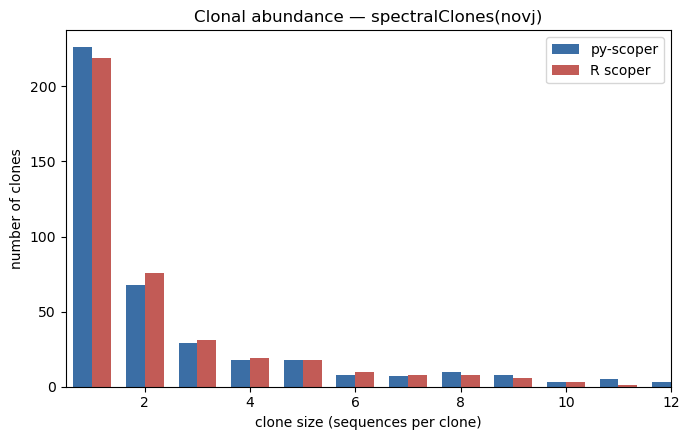

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
py_sizes = py_novj["clone_id"].value_counts().value_counts().sort_index()
ax.bar(py_sizes.index - 0.18, py_sizes.values, width=0.36,
       label="py-scoper", color="#3b6ea5")
if r_ok and (r_dir / "spectral_novj.csv").exists():
    r = pd.read_csv(r_dir / "spectral_novj.csv")
    r_sizes = r["clone_id"].value_counts().value_counts().sort_index()
    ax.bar(r_sizes.index + 0.18, r_sizes.values, width=0.36,
           label="R scoper", color="#c25b56")
ax.set_xlim(0.5, 12)
ax.set_xlabel("clone size (sequences per clone)")
ax.set_ylabel("number of clones")
ax.set_title("Clonal abundance — spectralClones(novj)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Distance-threshold plot

`plotCloneSummary` — the inter- vs intra-clone normalized-Hamming-distance
distribution with the effective clonal-distance threshold marker.

py effective threshold: 0.22
R  effective threshold: 0.22


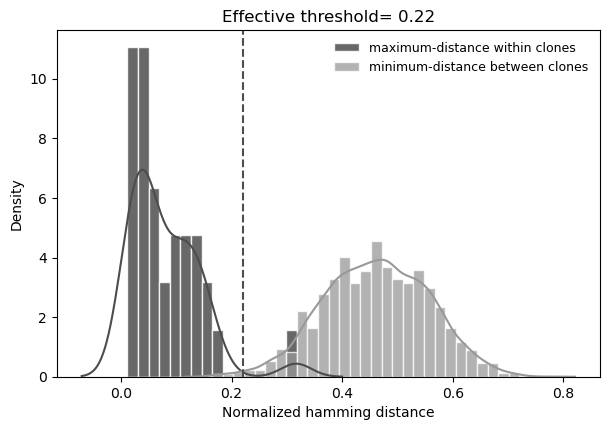

In [7]:
res = sc.hierarchicalClones(db, threshold=0.15, summarize_clones=True)
print("py effective threshold:", res.eff_threshold)
if r_ok and (r_dir / "eff_threshold.csv").exists():
    r_eff = float(pd.read_csv(r_dir / "eff_threshold.csv")
                  ["eff_threshold"].iloc[0])
    print("R  effective threshold:", r_eff)

ax = sc.plotCloneSummary(res, silent=True)
plt.show()

## 7. Summary

`py-scoper` reproduces R scoper 1.5.0:

* **identicalClones / hierarchicalClones** — deterministic, exact partition
  (ARI = 1.0).
* **spectralClones (novj / vj)** — stochastic k-means, ARI > 0.95 with clone
  counts within a few percent of scoper.
* **effective threshold** — exact agreement (0.22 on ExampleDb).